## *The Lore of the Project:*
The story behind this research originates in the early 1970s with an anthropological study conducted by **Wayne W. Zachary**, then a graduate student exploring how friendships and alliances develop inside small social groups.


#### The Fieldwork and Social Network:
For two years, Zachary observed the social interactions among 34 members of a university karate club in the United States.
He documented who interacted outside of class, training together, attending social gatherings, and spending casual leisure time as friends.
*By placing an **edge** between any two members who interacted frequently, he constructed a **34-node, 78-edge** social network*


#### The Conflict and the Faction Split:
During the field research, an internal conflict erupted between two central figures: **The club's instructor -Mr. Hi and the club's president**.
The dispute centered on financial governance. As tensions escalated, the club fractured into two opposing factions, forcing every member to choose whether to align with Mr. Hi or the president

#### Zachary's Findings and what it Meant:
When the formal split occurred, Zachary discovered that the friendship network he had recorded prior to the conflict strongly predicted the faction each member chose: friends consistently stuck together.
Because the real-world outcome provided an objective ground truth collected after the initial relational data, the Karate Club network became the classic "hello world" benchmark for network science and community detection. It established a foundational challenge for mathematicians and data scientists: determining whether purely structural graph algorithms—such as spectral modularity optimization—can mathematically detect latent social fault lines and reconstruct real-world community splits.


In [19]:
# Install missing libraries if not already installed.
import importlib
import importlib.util
import subprocess
import sys

required_packages = { "numpy": "numpy", "pandas": "pandas","matplotlib": "matplotlib",
    "networkx": "networkx","IPython": "ipython",}

print("Checking required packages...")
missing_libraries = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_libraries:
    print("Installing missing packages:", ", ".join(missing_libraries), flush=True)
    try:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "--quiet", *missing_libraries
        ])
        importlib.invalidate_caches()
        print("Missing packages installed successfully.")
    except subprocess.CalledProcessError as exc:
        raise RuntimeError(
            "Package installation failed. Check internet access and the pip message above. "
            "If Python is externally managed, select a virtual-environment kernel "
            "with the required packages installed, then rerun from the first cell."
        ) from exc
else:
    print("All required libraries are already installed.")

print("Dependency check complete.")

Checking required packages...
All required libraries are already installed.
Dependency check complete.


In [65]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

G = nx.karate_club_graph() # importing the karate club graph from networkx

for u, v, data in G.edges(data=True): # removing the weight attribute from the edges of the graph
    data.pop("weight", None)

n = G.number_of_nodes()
m = G.number_of_edges()
print("Nodes:", n, "Edges:", m)

A = nx.to_numpy_array(G, weight=None) # converting the graph to an adjacency matrix   
k = A.sum(axis=1)                       
B = A - np.outer(k, k) / (2 * m)

eigenvalues, eigenvectors = np.linalg.eigh(B)

lam = eigenvalues[-1]          
u = eigenvectors[:, -1]        

print("largest eigenvalue:", lam)

group1 = [i for i in range(n) if u[i] > 0]
group2 = [i for i in range(n) if u[i] <= 0]
print("First split by the sign of the leading eigenvector:")
print("  Group 1 (", len(group1), "nodes):", group1)
print("  Group 2 (", len(group2), "nodes):", group2)

# Modularity of this split: Q = s^T B s / (4m)
s = np.where(u > 0, 1, -1)
Q = s @ B @ s / (4 * m)
print("Q =", Q)

Nodes: 34 Edges: 78
largest eigenvalue: 4.977080225729886
First split by the sign of the leading eigenvector:
  Group 1 ( 16 nodes): [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
  Group 2 ( 18 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Q = 0.37146614069691


### Note on the splitting rule: a deliberate difference from the handout


The handout tests a group C using the leading eigenvalue of the raw sub-block B(C) of the modularity matrix. Newman (2006) shows that the modularity gain from splitting a group *inside a larger partition* is governed by a corrected matrix, M = B(C) − diag(row sums of B(C)), so that ΔQ = sᵀMs / 4m. For the whole graph the row sums of B are zero, so M = B and the first split is identical to the handout's. For a subgroup the row sums are not zero, so using the raw block would not measure the real gain. This code therefore uses M for every split after the first.


A positive leading eigenvalue is also not enough to accept a split. The eigenvector solves a relaxed problem (real-valued entries), and rounding it to ±1 can lose enough that the actual split makes Q worse. For example, the 9-node group {1, 2, 3, 7, 12, 13, 17, 19, 21} has a leading eigenvalue of 0.0602, but splitting it by sign gives ΔQ = −0.0158. `propose_split` therefore stops a group if (1) the leading eigenvalue is not positive, (2) one side of the split is empty, or (3) the actual gain sᵀMs / 4m is not positive.


In [66]:
### Note on the splitting rule: a deliberate difference from the handout
def propose_split(group):
    """group: list of node numbers. Returns (child1, child2, gain) or None."""
    R = B[np.ix_(group, group)]            # B restricted to this group
    M = R - np.diag(R.sum(axis=1))         # the correction

    values, vectors = np.linalg.eigh(M)
    if values[-1] <= 1e-10:                # no positive eigenvalue: stop
        return None

    u = vectors[:, -1]
    s = np.where(u > 0, 1, -1)
    child1 = [g for g, sign in zip(group, s) if sign == 1]
    child2 = [g for g, sign in zip(group, s) if sign == -1]
    if len(child1) == 0 or len(child2) == 0:   # all on one side: stop
        return None

    gain = s @ M @ s / (4 * m)
    if gain <= 1e-10:                      # split doesn't actually help: stop
        return None
    return child1, child2, gain


def recursive_split(group):
    result = propose_split(group)
    if result is None:
        return [group]                      # can't split: this is a final community
    child1, child2, gain = result
    return recursive_split(child1) + recursive_split(child2)

communities = recursive_split(list(range(n)))

final_table = pd.DataFrame({
    "community": [f"C{i+1}" for i in range(len(communities))],
    "size": [len(c) for c in communities],
    "nodes": [sorted(c) for c in communities],
})
display(final_table.set_index("community"))


def modularity(partition):
    total = 0
    for c in partition:
        internal_edges = G.subgraph(c).number_of_edges()
        degree_sum = sum(G.degree(v) for v in c)
        total += internal_edges / m - (degree_sum / (2 * m)) ** 2
    return total

print("Q from my own function:     ", round(modularity(communities), 6))
print("Q from NetworkX (check):    ", round(nx.community.modularity(G, communities), 6))

,size,nodes
community,,
C1,7,"[0, 4, 5, 6, 10, 11, 16]"
C2,9,"[1, 2, 3, 7, 12, 13, 17, 19, 21]"
C3,12,"[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]"
C4,6,"[23, 24, 25, 27, 28, 31]"


Q from my own function:      0.393409
Q from NetworkX (check):     0.393409


,communities,sizes,Q,gain
iteration,,,,
0,1,[34],0.0000,NaN
1,2,"[16, 18]",0.3715,0.3715
2,3,"[7, 9, 18]",0.3727,0.0012
3,4,"[7, 9, 12, 6]",0.3934,0.0207


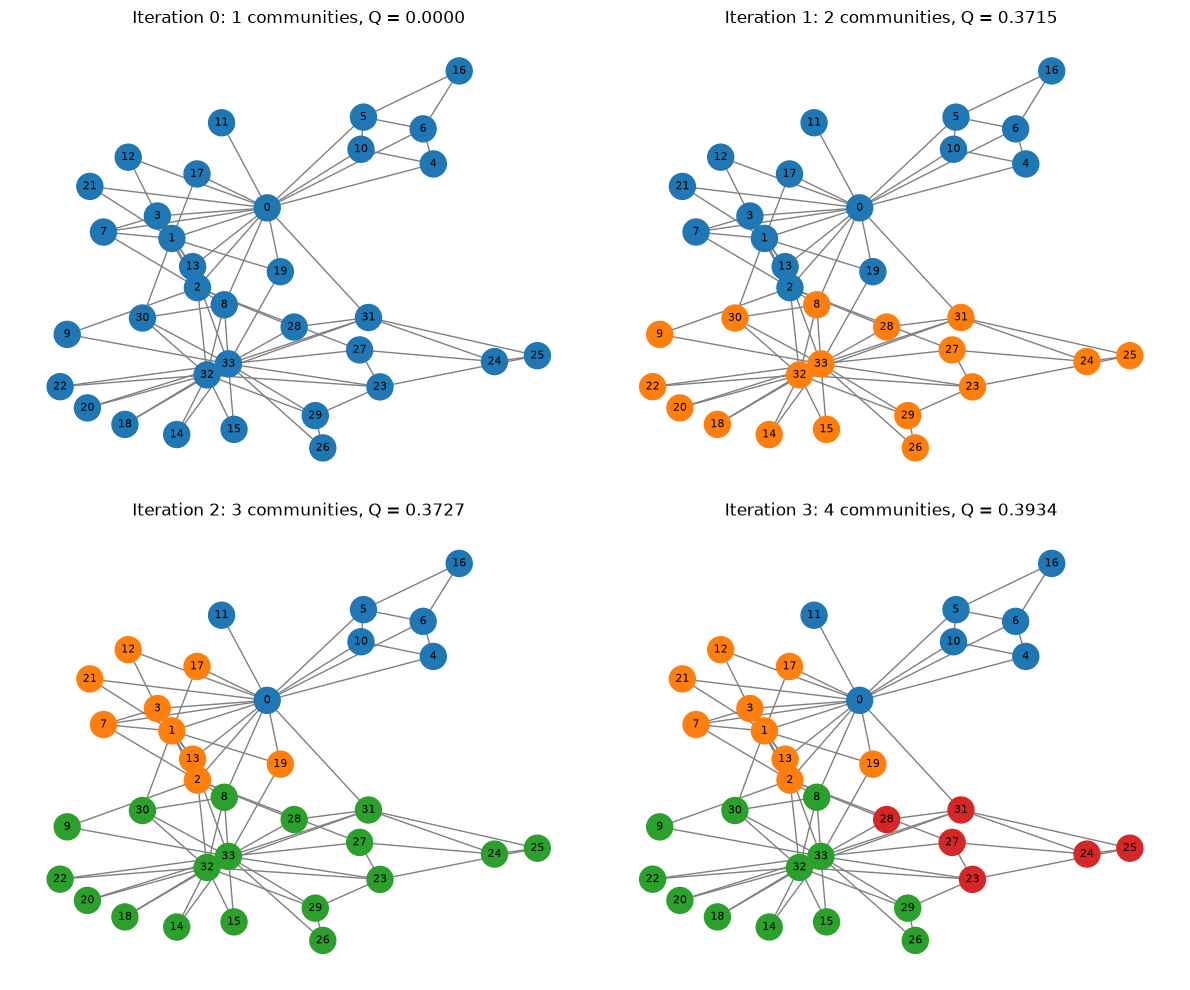

In [67]:
current = [list(range(n))]                 # start: everyone in one group
history = [[g.copy() for g in current]]    # history[0] = before any split
gains = []

while True:
    split_found = False
    for i, group in enumerate(current):
        result = propose_split(group)
        if result is not None:
            child1, child2, gain = result
            # sort children so the order is the same every run
            child1, child2 = sorted([sorted(child1), sorted(child2)],
                                    key=lambda c: c[0])
            current = current[:i] + [child1, child2] + current[i+1:]
            history.append([g.copy() for g in current])
            gains.append(gain)
            split_found = True
            break                          # restart the search after each split
    if not split_found:
        break                              # nothing can split: done



summary = pd.DataFrame({
    "iteration": range(len(history)),
    "communities": [len(p) for p in history],
    "sizes": [[len(g) for g in p] for p in history],
    "Q": [round(modularity(p), 4) for p in history],
    "gain": [np.nan] + [round(g, 4) for g in gains],
})
display(summary.set_index("iteration"))



pos = nx.spring_layout(G, seed=42)         # computed ONCE, reused everywhere

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for t, (partition, ax) in enumerate(zip(history, axes.flat)):
    color_of = {}
    for ci, group in enumerate(partition):
        for v in group:
            color_of[v] = plt.cm.tab10(ci)

    nx.draw_networkx(G, pos, ax=ax,
                     node_color=[color_of[v] for v in G.nodes()],
                     with_labels=True, node_size=350, font_size=8,
                     edge_color="gray")
    ax.set_title(f"Iteration {t}: {len(partition)} communities, "
                 f"Q = {modularity(partition):.4f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Circles (nodes)**: Each represents a member of the karate club.                                                                                           
**Numbers**: Labeling individual members, from 0 to 33.                                                                                                       
**Lines(edges)**: Represent friendships or connections between members.                                                                                              
**Colours**: Represent the different communities identified by the algorithm.                        
                                                                                                                         **Q** : Modularity(A measure of how well the community is split)

*Iteration 0*: at Q = 0, all individuals belong to one community, i.e. before the split.                                                                      
*Iteration 1*: at Q = 0.3715, 2 communities have been formed.                                                                                                        
*Iteration 2*: at Q = 0.3727, 3 communities have been formed                                                                                                           
*Iteration 3*: at Q = 0.3934, 4 communities have been formed

The increasing modularity values indicate that the **successive divisions improve the community structure according to the modularity** measure.                  
The final result demonstrates how **recursive spectral partitioning can identify smaller groups within a larger network** using the modularity matrix and its eigenvectors.

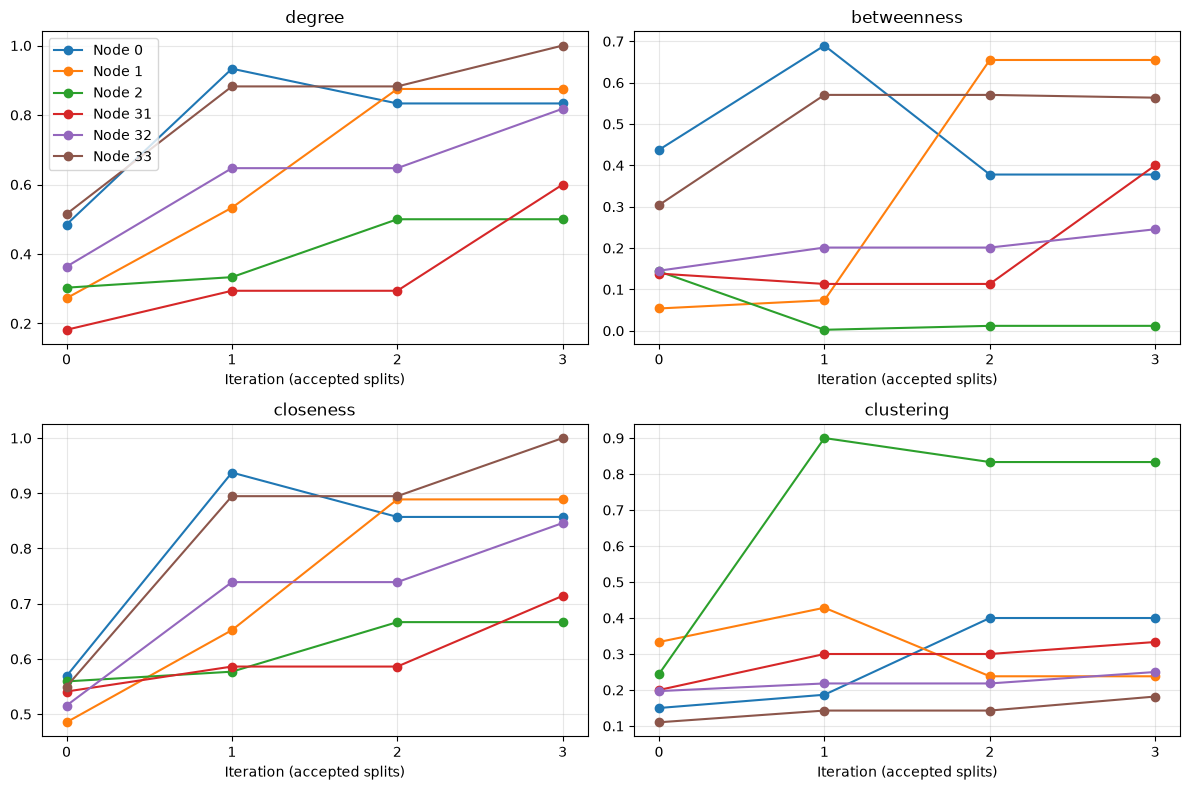

In [68]:
metric_funcs = {
    "degree": nx.degree_centrality,
    "betweenness": nx.betweenness_centrality,
    "closeness": nx.closeness_centrality,
    "clustering": nx.clustering,
}

global_metrics = {}   # global_metrics[t]["degree"][node]
local_metrics = {}    # local_metrics[t]["degree"][node]

for t, partition in enumerate(history):
    global_metrics[t] = {name: f(G) for name, f in metric_funcs.items()}

    local_metrics[t] = {name: {} for name in metric_funcs}
    for group in partition:
        H = G.subgraph(group)                 # only this community's nodes and edges
        for name, f in metric_funcs.items():
            local_metrics[t][name].update(f(H))


iterations = list(range(len(history)))
focus = [0, 1, 2, 31, 32, 33]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for name, ax in zip(metric_funcs, axes.flat):
    for v in focus:
        values = [local_metrics[t][name][v] for t in iterations]
        ax.plot(iterations, values, "o-", label=f"Node {v}")
    ax.set_title(name)
    ax.set_xticks(iterations)
    ax.set_xlabel("Iteration (accepted splits)")
    ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Results and Discussion: Evolution of Network Metrics

The recursive spectral clustering algorithm was applied to the Zachary Karate Club graph to identify communities and study how the structural importance of individual nodes changes as the network is partitioned.

The algorithm began with all 34 nodes in a single community. It subsequently divided the network into smaller communities, resulting in four communities after three accepted splits.

The evolution of modularity was as follows:

| Iteration | Number of Communities | Modularity (Q) |
|---|---:|---:|
| 0 | 1 | 0.0000 |
| 1 | 2 | 0.3715 |
| 2 | 3 | 0.3727 |
| 3 | 4 | 0.3934 |

The increase in modularity indicates that the successive partitions improve the community structure according to the modularity measure.

### 1. Degree Centrality

Degree centrality measures the number of direct connections a node has relative to the maximum possible number of connections within its community.

The mathematical formula is:


$$
C_D(v)=\frac{k_v}{n-1}
$$


Where:
- $C_D(v)$ = Degree centrality of node $v$.
- $k_v$ = Number of direct connections of node $v$.
- $n$ = Number of nodes in the community.

The degree centrality values change as the network is divided into smaller communities. For example, Node 33 reaches a degree centrality of 1.0 in the final iteration. This indicates that it is directly connected to every other node in its community.

The changes demonstrate that a node's relative connectivity depends on the community in which it is evaluated.

### 2. Betweenness Centrality

Betweenness centrality measures how frequently a node lies on the shortest paths between pairs of other nodes.

Its mathematical formula is:


$$
C_B(v)=
\sum_{\substack{s\neq v\neq t\\s<t}}
\frac{\sigma_{st}(v)}{\sigma_{st}}
$$


Where:
- $C_B(v)$ = Betweenness centrality of node $v$.
- $\sigma_{st}$ = Number of shortest paths between nodes $s$ and $t$.
- $\sigma_{st}(v)$ = Number of those shortest paths that pass through node $v$.
A high betweenness centrality indicates that a node plays an important role in connecting different parts of a network.

The plots show that Node 0 initially has relatively high betweenness centrality. Node 0’s betweenness rises at the first split (about 0.44 to 0.69) and falls at the second (to about 0.38). Node 1, on the other hand, becomes increasingly important within its community.

This demonstrates how the role of a node as a connecting point can change when the network is divided into smaller communities.

### 3. Closeness Centrality

Closeness centrality measures how close a node is to all other reachable nodes in its community, based on shortest-path distances.

For a connected community, its mathematical formula is:


$$
C_C(v)=\frac{n-1}
{\sum_{u\neq v}d(v,u)}
$$


Where:

- $C_C(v)$= Closeness centrality of node $v$.
- $n$ = Number of nodes in the community.
- $d(v,u)$ = Shortest-path distance between nodes $v$ and $u$.

A higher closeness centrality indicates that a node can reach other members of its community more efficiently.

The results show that the closeness centrality of certain nodes increases as the network is partitioned. For example, Node 33 reaches a value of 1.0 in the final iteration, indicating that it is directly connected to every other node in its community.

This illustrates how a node can become more central within a smaller community than it was in the original network.

### 4. Clustering Coefficient

The clustering coefficient measures how interconnected the neighbours of a particular node are.

Its mathematical formula is:


$$
C(v)=\frac{2T(v)}{k_v(k_v-1)}
$$


Where:

- $C(v)$ = Clustering coefficient of node $v$.
- $T(v)$ = Number of edges between the neighbours of node $v$.
- $k_v$ = Number of neighbours of node $v$.

The clustering coefficient ranges between 0 and 1.

- A value of 0 indicates that none of the node's neighbours are connected to one another.
- A value of 1 indicates that all of its neighbours are connected to one another.

The results show that different nodes have different levels of local interconnectedness. For example, Node 2 has a particularly high clustering coefficient, reaching approximately 0.9 after the first partition.

This indicates that its neighbours form a closely interconnected group.

### 5. Overall Interpretation

The four network metrics describe different aspects of the structural importance of nodes:

| Metric | Structural significance |
|---|---|
| Degree centrality | Measures direct connectivity. |
| Betweenness centrality | Measures the importance of a node in connecting other nodes through shortest paths. |
| Closeness centrality | Measures how efficiently a node can reach other nodes. |
| Clustering coefficient | Measures how interconnected a node's neighbours are. |

The results demonstrate that a node can be important in one aspect of network structure but less important in another. For instance, a node may have many direct connections but may not necessarily act as an important bridge between other nodes.

As the network is recursively partitioned, the values of these metrics change because they are calculated within the individual communities rather than across the entire original graph.

### 6. Conclusion

The recursive spectral clustering algorithm successfully identified four communities in the Zachary Karate Club graph, producing a final modularity value of approximately 0.3934.

The evolution plots demonstrate that the structural roles of individual nodes change as the network is divided into smaller communities. The four network metrics provide complementary information about connectivity, shortest-path relationships and local interconnectedness.

Overall, the results demonstrate how spectral methods and network centrality measures can be combined to identify community structure and analyse the importance of individual nodes in a social network.

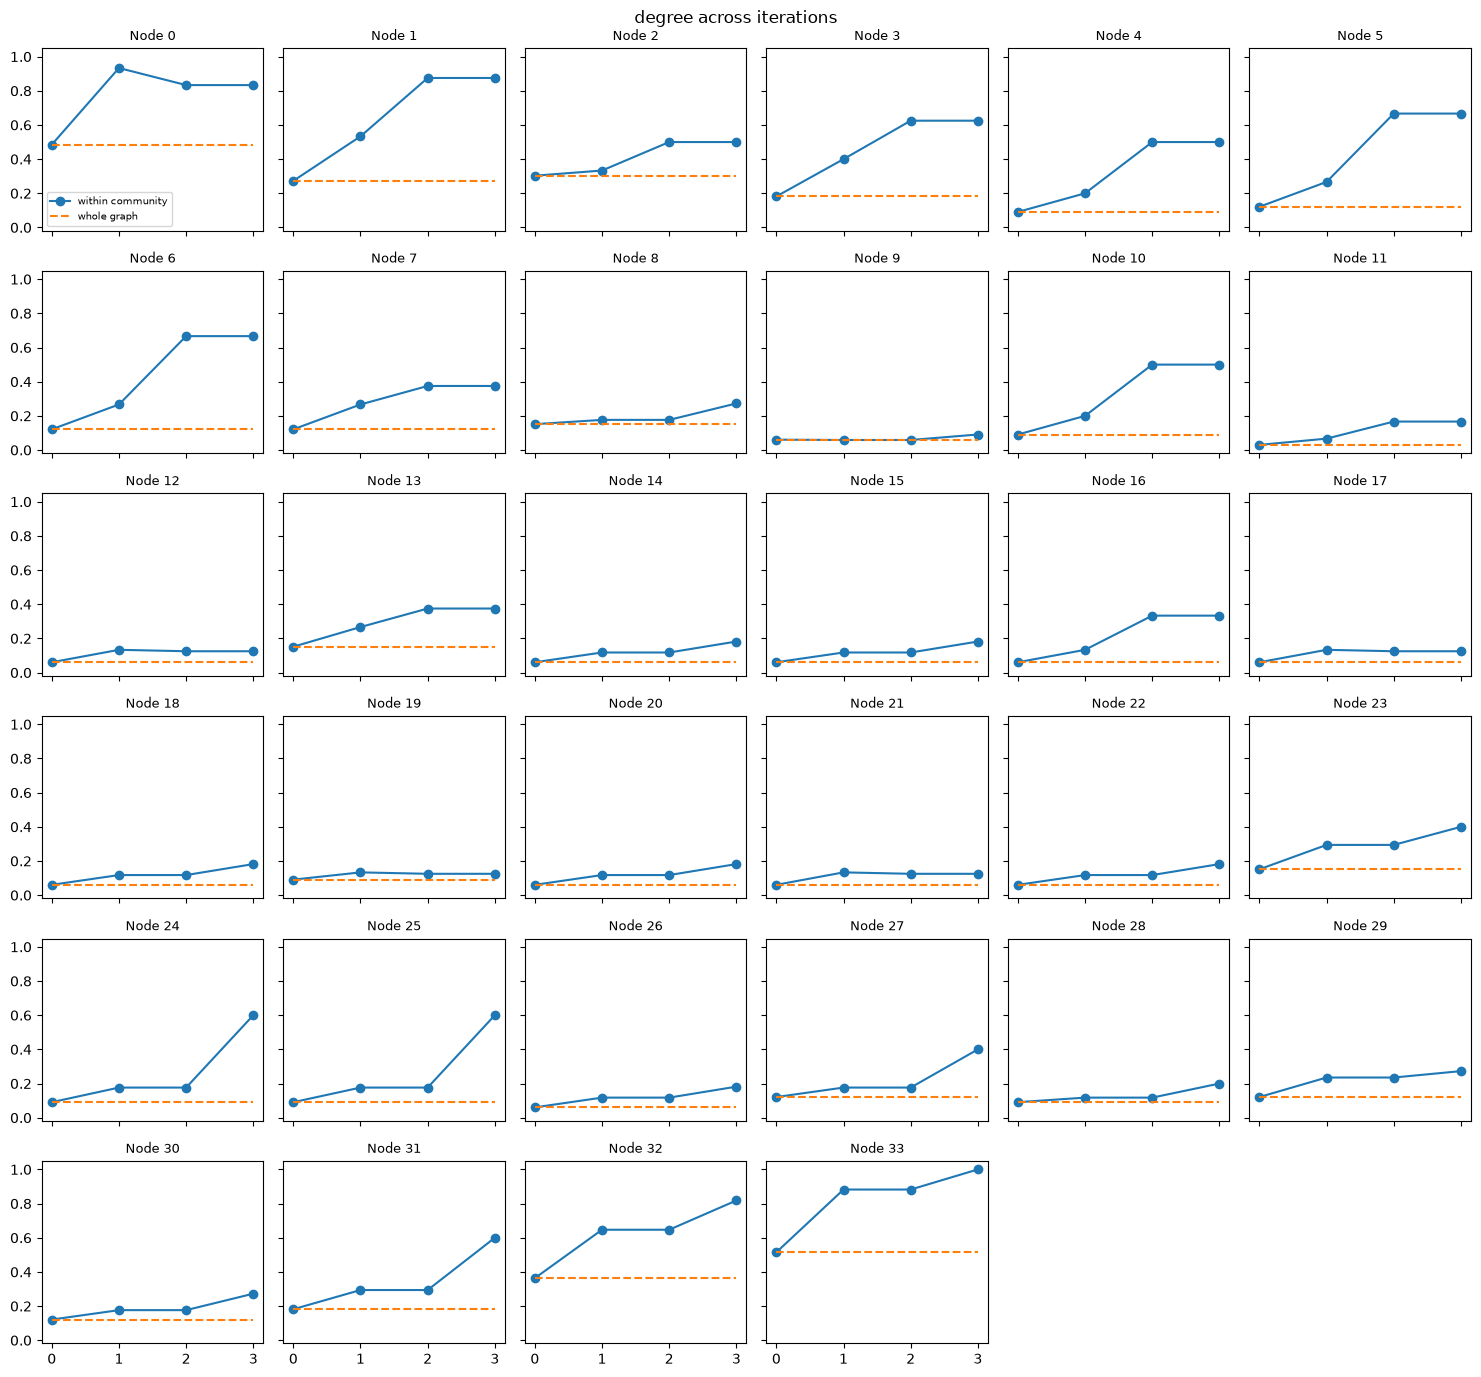

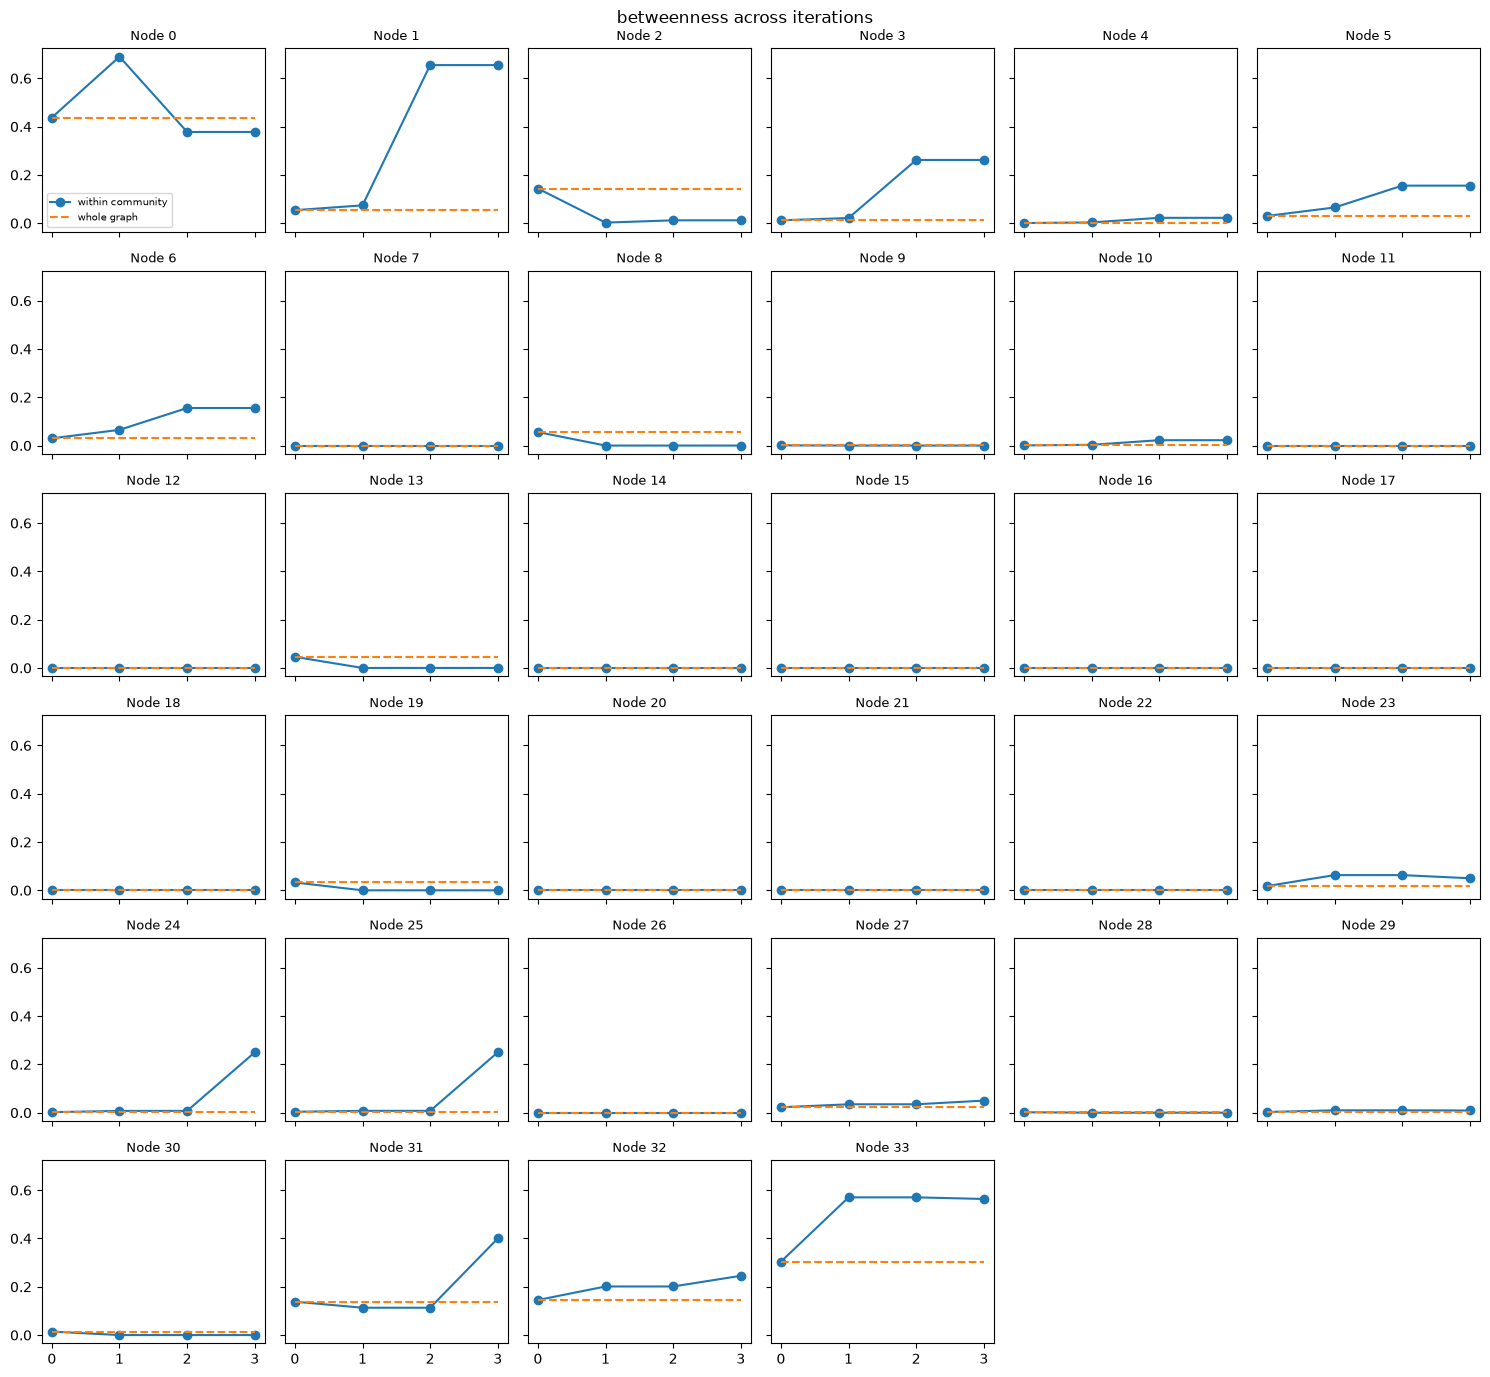

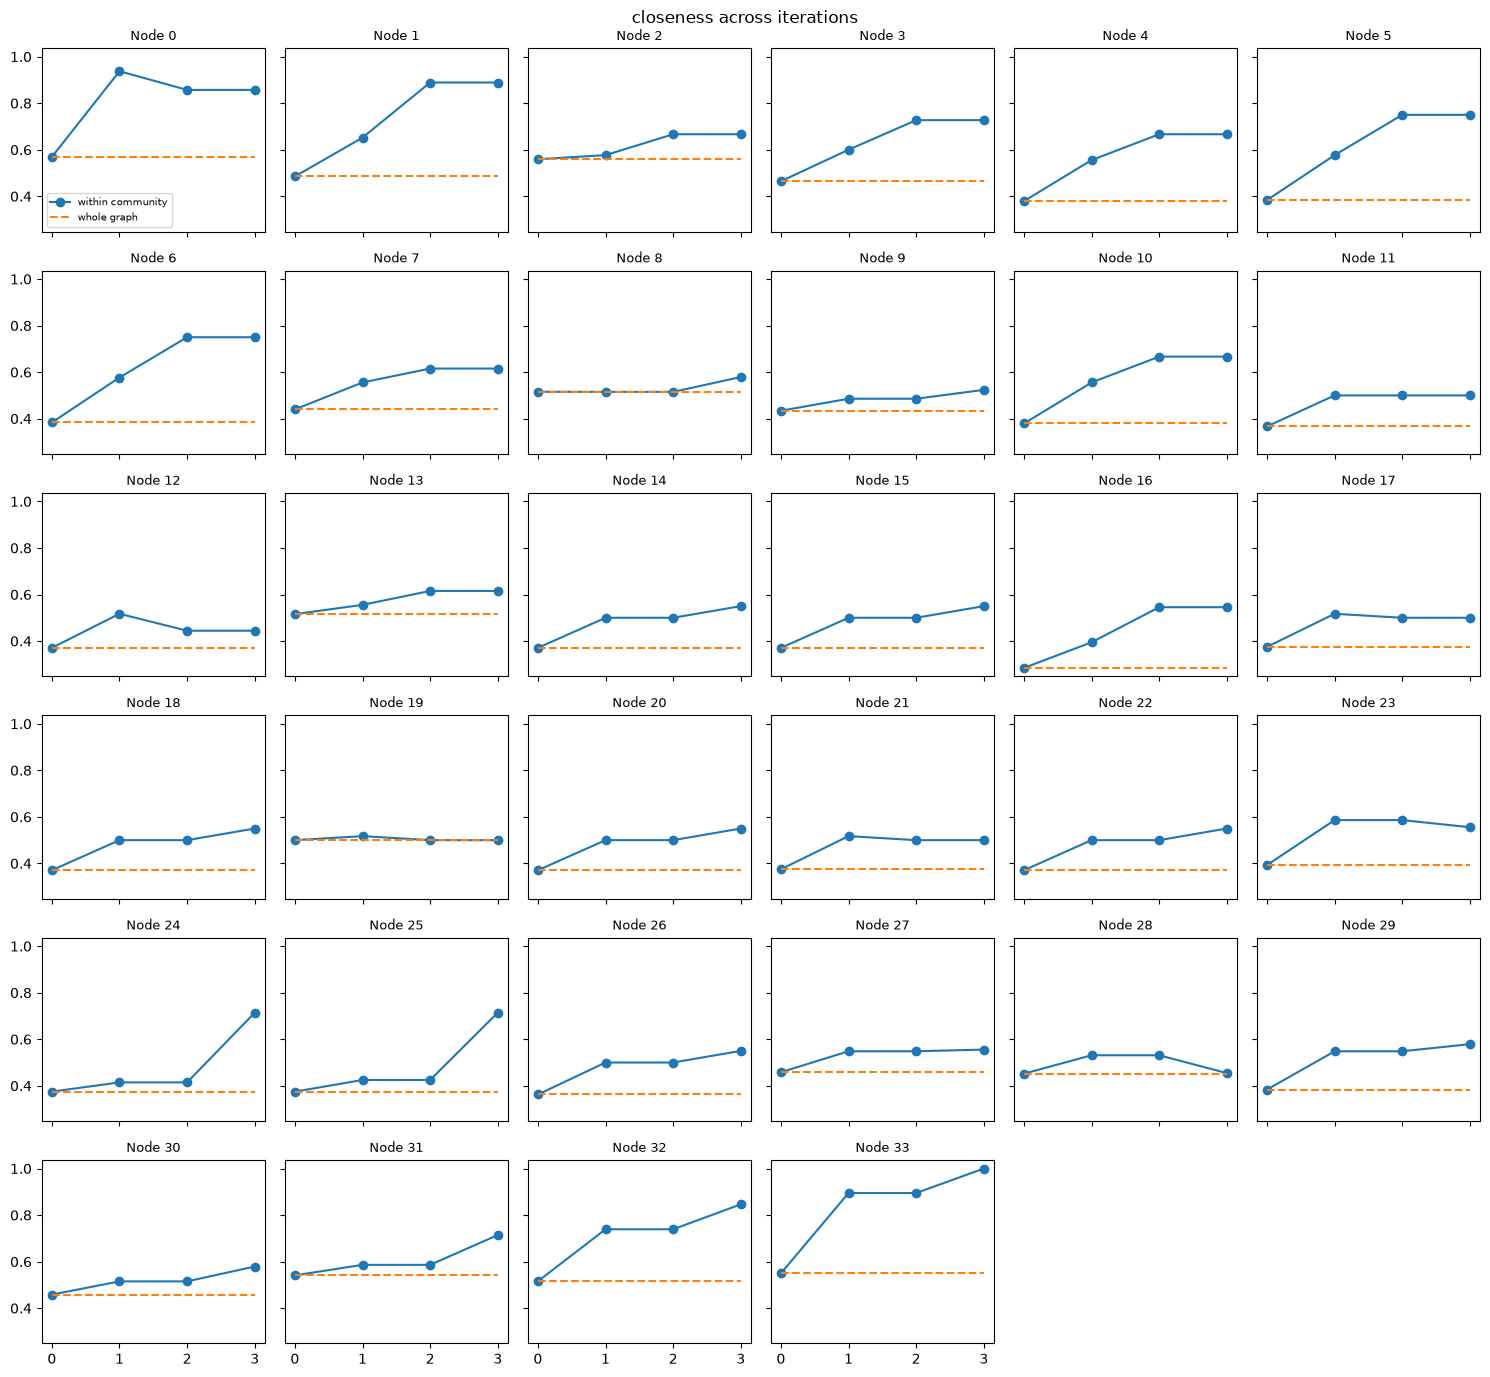

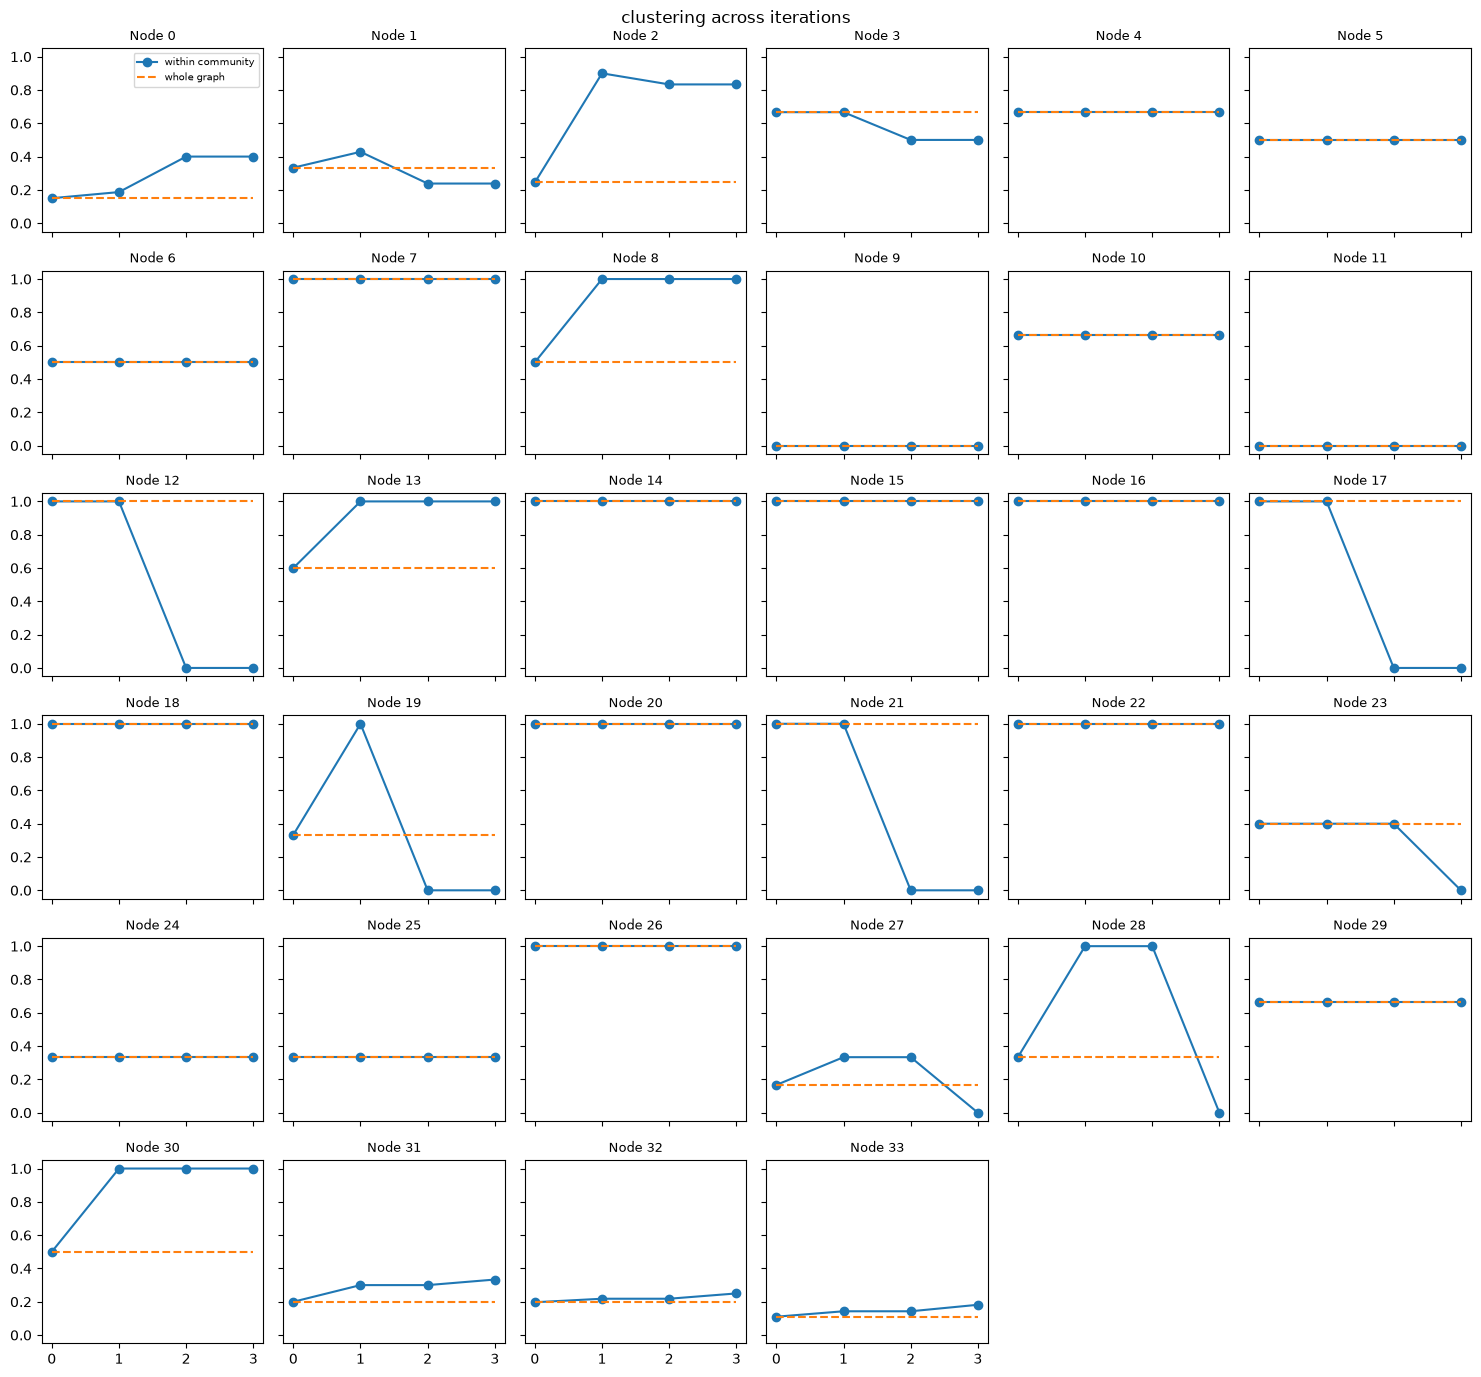

In [69]:
def plot_all_nodes(name):
    fig, axes = plt.subplots(6, 6, figsize=(15, 14), sharex=True, sharey=True)
    for v, ax in zip(range(n), axes.flat):
        local_y  = [local_metrics[t][name][v]  for t in iterations]
        global_y = [global_metrics[t][name][v] for t in iterations]
        ax.plot(iterations, local_y, "o-", label="within community")
        ax.plot(iterations, global_y, "--", label="whole graph")
        ax.set_title(f"Node {v}", fontsize=9)
        ax.set_xticks(iterations)
    for ax in list(axes.flat)[n:]:      # 36 panels, only 34 nodes: hide the last two
        ax.axis("off")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"{name} across iterations")
    plt.tight_layout()
    plt.show()

for name in metric_funcs:
    plot_all_nodes(name)

In [70]:
import pandas as pd

rows = []
for name in ["degree", "betweenness", "closeness"]:
    for t, partition in enumerate(history):
        for group in partition:
            best = max(local_metrics[t][name][v] for v in group)
            for v in group:
                if np.isclose(local_metrics[t][name][v], best):
                    rows.append({"metric": name, "iteration": t, "node": v})
leaders = pd.DataFrame(rows)

# Table 1: who leads at each iteration
table1 = (leaders.groupby(["metric", "iteration"])["node"]
          .apply(lambda s: ", ".join(map(str, sorted(s))))
          .unstack("iteration"))
display(table1)

# Table 2: in how many iterations did each node lead?
table2 = leaders.groupby(["node", "metric"]).size().unstack("metric", fill_value=0)
table2 = table2.sort_values(list(table2.columns), ascending=False)
display(table2)

iteration,0,1,2,3
metric,,,,
betweenness,0,"0, 33","0, 1, 33","0, 1, 31, 33"
closeness,0,"0, 33","0, 1, 33","0, 1, 24, 25, 31, 33"
degree,33,"0, 33","0, 1, 33","0, 1, 24, 25, 31, 33"


metric,betweenness,closeness,degree
node,,,
0,4,4,3
33,3,3,4
1,2,2,2
31,1,1,1
24,0,1,1
25,0,1,1


# Inference and Observations:

Nodes 0 and 33 stay central across the splits. Node 0 has the highest betweenness and closeness in its community at all four iterations, and node 33 has the highest degree at all four; these are the instructor (Mr. Hi) and the club president, the leaders of the two factions. 

Other nodes become central only when a split removes the hubs from their group: node 1 leads its community from iteration 2, when node 0 is in a different group, and node 31 leads in betweenness at iteration 3, when node 33 is in a different group. Community structure also changes the metrics themselves, because each is computed only on the nodes inside a community. 

Node 2’s betweenness falls from about 0.14 to about 0.002 at iteration 1, because five of its ten neighbours are now outside its group and the paths between the remaining ones bypass it. 
Degree and closeness rise for most nodes as groups shrink, partly because the same connections are counted against fewer nodes.

# References
Newman, M. E. J. (2006). Modularity and community structure in networks. PNAS, 103(23), 8577–8582.


Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. Journal of Anthropological Research, 33(4), 452–473.